# Longitud real del pez en cm: función wrapper `medir_peces`

Misma lógica que `fish_length_cm.ipynb` (YOLO seg → esqueleto Lantuéjoul → polinomio PCA → extremos con convex hull → homografía ArUco → cm), pero empaquetada en **una sola función**:

```python
res = medir_peces("example_2.jpg", graficar=True, ruta_salida="resultado.png")
```

Todos los valores que antes estaban hardcodeados (pesos, confianza, tamaño del ArUco, grado del polinomio, colores, qué dibujar...) son parámetros con el mismo valor por defecto.

In [1]:
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes
from ultralytics import YOLO

KERNEL_3x3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
KERNEL_CROSS = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
_MODELS = {}   # cache de modelos por ruta de pesos (para no recargar en cada llamada)


def _get_model(weights):
    key = str(weights)
    if key not in _MODELS:
        _MODELS[key] = YOLO(weights)
    return _MODELS[key]


# ---------------------------------------------------------------- máscaras + esqueleto
def get_clean_mask(mask):
    """Rellena huecos internos y suaviza bordes rugosos de la máscara."""
    filled_bool = binary_fill_holes(mask > 0)
    filled_mask = (filled_bool * 255).astype(np.uint8)
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    return cv2.morphologyEx(filled_mask, cv2.MORPH_CLOSE, kernel_close)


def skeletonize(mask, verbose=False):
    """Esqueleto morfológico (Lantuéjoul) sobre una máscara limpia y sólida."""
    t0 = time.perf_counter()
    img = get_clean_mask(mask)
    skel = np.zeros_like(img)
    while cv2.countNonZero(img) > 0:
        eroded = cv2.erode(img, KERNEL_CROSS)
        opened = cv2.dilate(eroded, KERNEL_CROSS)
        skel = cv2.bitwise_or(skel, cv2.subtract(img, opened))
        img = eroded
    if verbose:
        print(f"skeletonize (Lantuéjoul): {time.perf_counter() - t0:.4f} s")
    return skel


def fish_masks(img_bgr, model, conf, imgsz):
    """Predice máscaras de instancia. Devuelve (masks, confs); masks: lista de arrays uint8 {0,255}."""
    h, w = img_bgr.shape[:2]
    res = model.predict(img_bgr, imgsz=imgsz, conf=conf, retina_masks=True, verbose=False)[0]
    masks = []
    if res.masks is None:
        return masks, []
    confs = res.boxes.conf.cpu().numpy().tolist()
    for m in res.masks.data.cpu().numpy():
        m = (m > 0.5).astype(np.uint8) * 255
        if m.shape != (h, w):
            m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        masks.append(m)
    return masks, confs


def detect_aruco(img_bgr, aruco_dict):
    """Busca marcadores ArUco. Devuelve (corners, ids); corners: lista de arrays (4, 2) float32."""
    detector = cv2.aruco.ArucoDetector(cv2.aruco.getPredefinedDictionary(aruco_dict), cv2.aruco.DetectorParameters())
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    corners, ids, _ = detector.detectMarkers(gray)
    if ids is None:
        return [], []
    return [c.reshape(4, 2) for c in corners], ids.flatten().tolist()


# ---------------------------------------------------------------- polinomio + extremos
def fit_centerline(skel, mask, deg):
    """Ajusta un polinomio de grado `deg` a los puntos del esqueleto en el sistema de ejes principales (PCA).
    Devuelve (curve, frame): curve(t) -> puntos (N, 2) en la imagen; frame = (centro, u, tmin, tmax) con
    tmin/tmax el rango de la MÁSCARA sobre el eje mayor."""
    ys, xs = np.nonzero(skel)
    pts = np.column_stack([xs, ys]).astype(np.float64)
    c = pts.mean(0)
    _, _, vt = np.linalg.svd(pts - c, full_matrices=False)
    u, v = vt[0], vt[1]
    t = (pts - c) @ u
    s = (pts - c) @ v
    scale = np.abs(t).max() or 1.0
    coef = np.polyfit(t / scale, s, deg)

    my, mx = np.nonzero(mask)
    mt = (np.column_stack([mx, my]) - c) @ u

    def curve(tt):
        tt = np.asarray(tt, dtype=np.float64)
        return c + np.outer(tt, u) + np.outer(np.polyval(coef, tt / scale), v)

    return curve, (c, u, mt.min(), mt.max())


def curve_hull_ends(curve, frame, hull, n_samples, margin=0.3):
    """Extremos de la curva: puntos donde el polinomio, prolongado desde el centro hacia cada lado, sale del convex hull."""
    _, _, tmin, tmax = frame
    L = tmax - tmin
    ts = np.linspace(tmin - margin * L, tmax + margin * L, n_samples)
    pts = curve(ts)
    inside = np.array([cv2.pointPolygonTest(hull, (float(x), float(y)), False) >= 0 for x, y in pts])
    i0 = int(np.argmin(np.abs(ts - (tmin + tmax) / 2)))
    if not inside[i0]:
        i0 = int(np.argmax(inside))
    ends = []
    for direction in (-1, 1):
        i = i0
        while 0 <= i + direction < len(ts) and inside[i + direction]:
            i += direction
        j = min(max(i + direction, 0), len(ts) - 1)
        lo, hi = ts[i], ts[j]
        for _ in range(30):
            mid = (lo + hi) / 2
            x, y = curve([mid])[0]
            if cv2.pointPolygonTest(hull, (float(x), float(y)), False) >= 0:
                lo = mid
            else:
                hi = mid
        ends.append(lo)
    return ends[0], ends[1]


def analyze_fish(mask, poly_deg, n_samples, verbose=False):
    """Esqueleto -> polinomio -> extremos con convex hull. Devuelve dict con los resultados de un pez."""
    skel = skeletonize(mask, verbose)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contour = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(contour)
    curve, frame = fit_centerline(skel, mask, poly_deg)
    t_a, t_b = curve_hull_ends(curve, frame, hull, n_samples)
    line = curve(np.linspace(t_a, t_b, 200))
    fit = curve(np.linspace(frame[2], frame[3], 200))
    length = float(np.sum(np.linalg.norm(np.diff(line, axis=0), axis=1)))
    return dict(skeleton=skel, fit=fit, contour=contour, hull=hull, line=line,
                end_a=line[0], end_b=line[-1], length_px=length)


# ---------------------------------------------------------------- homografía y cm
def homography_px_to_cm(aruco_corners_px, tamano_aruco_cm):
    """Homografía H (3x3) de píxeles a cm a partir de las 4 esquinas del ArUco detectado (array (4, 2))."""
    aruco_cm = np.array([(0, 0), (tamano_aruco_cm, 0), (tamano_aruco_cm, tamano_aruco_cm), (0, tamano_aruco_cm)],
                        dtype=np.float32)
    src = np.asarray(aruco_corners_px, dtype=np.float32).reshape(4, 2)
    H, _ = cv2.findHomography(src, aruco_cm)
    if H is None:
        raise ValueError("No se pudo calcular la homografía con las esquinas del ArUco")
    return H


def longitud_pez_cm(curve_px, H):
    """Longitud (cm) de la curva discretizada `curve_px` (N, 2) en píxeles: proyecta con H y suma distancias."""
    pts = np.asarray(curve_px, dtype=np.float32).reshape(-1, 1, 2)
    pts_cm = cv2.perspectiveTransform(pts, np.asarray(H, dtype=np.float64)).reshape(-1, 2)
    return float(np.sum(np.linalg.norm(np.diff(pts_cm, axis=0), axis=1)))


# ---------------------------------------------------------------- dibujo
def plot_length_cm(img_bgr, results, confs, aruco_corners, aruco_ids, *, tamano_aruco_cm, poly_deg,
                   show_convex, show_mask_contour, show_mask_full, show_skeleton, show_length,
                   skeleton_color, border_color, aruco_color, hull_color, poly_color, ends_color,
                   mask_fill_alpha, ruta_salida=None, mostrar=True):
    """Dibuja lo activado en show_* más confianza y largo en cm por pez y el tamaño del ArUco."""
    out = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    thickness = max(2, round(max(out.shape[:2]) / 400))
    font_scale = thickness / 3
    if show_mask_full:
        overlay = out.copy()
        for r in results:
            cv2.drawContours(overlay, [r["contour"]], -1, border_color, thickness=cv2.FILLED)
        out = cv2.addWeighted(overlay, mask_fill_alpha, out, 1 - mask_fill_alpha, 0)
    for r, conf in zip(results, confs):
        if show_skeleton:
            out[r["skeleton"] > 0] = skeleton_color
        if show_mask_contour:
            cv2.polylines(out, [r["contour"]], True, border_color, max(1, thickness // 2))
        if show_convex:
            cv2.polylines(out, [r["hull"]], True, hull_color, max(1, thickness // 2))
        if show_length:
            cv2.polylines(out, [np.round(r["line"]).astype(np.int32).reshape(-1, 1, 2)], False, poly_color, thickness)
            for p in (r["end_a"], r["end_b"]):
                cv2.circle(out, tuple(np.round(p).astype(int)), 3 * thickness, ends_color, -1)
        x, y, w, _ = cv2.boundingRect(r["contour"])
        txt = f"{conf:.2f} | {r['length_cm']:.2f} cm"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        x = int(np.clip(x + w / 2 - tw / 2, 0, out.shape[1] - tw))
        cv2.putText(out, txt, (x, int(max(y - 2 * thickness, th))), cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale, border_color, thickness)
    for c, i in zip(aruco_corners, aruco_ids):
        cv2.polylines(out, [c.astype(np.int32)], isClosed=True, color=aruco_color, thickness=thickness)
        txt = f"{tamano_aruco_cm:g} cm"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        cx, cy = c.mean(0)
        cv2.putText(out, txt, (int(cx - tw / 2), int(cy + th / 2)), cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale, (255, 255, 255), thickness)
    plt.figure(figsize=(12, 8))
    plt.imshow(out)
    plt.title(f"{len(results)} peces | largo en cm (ArUco {tamano_aruco_cm:g} cm) | grado polinomio {poly_deg}")
    plt.axis("off")
    if ruta_salida is not None:
        plt.savefig(ruta_salida, bbox_inches="tight", dpi=300)
        print(f"Imagen guardada como: {ruta_salida}")
    if mostrar:
        plt.show()
    else:
        plt.close()
    return out

def plot_aruco_error(img_bgr, aruco_corners, aruco_ids, aruco_id_esperado, ruta_salida=None, mostrar=True):
    """Marca en rojo los ArUco detectados con ID distinto al esperado: 'ArUco erroneo - ID = {id}'."""
    out = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    thickness = max(2, round(max(out.shape[:2]) / 400))
    font_scale = thickness / 3
    for c, i in zip(aruco_corners, aruco_ids):
        cv2.polylines(out, [c.astype(np.int32)], isClosed=True, color=(255, 0, 0), thickness=thickness)
        txt = f"ArUco erroneo - ID = {i}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        x = int(np.clip(c[:, 0].mean() - tw / 2, 0, out.shape[1] - tw))
        y = int(max(c[:, 1].min() - 2 * thickness, th))
        cv2.putText(out, txt, (x, y), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 0, 0), thickness)
    plt.figure(figsize=(12, 8))
    plt.imshow(out)
    plt.title(f"No se encontró el ArUco con ID = {aruco_id_esperado} | detectados: {list(aruco_ids)}")
    plt.axis("off")
    if ruta_salida is not None:
        plt.savefig(ruta_salida, bbox_inches="tight", dpi=300)
        print(f"Imagen guardada como: {ruta_salida}")
    if mostrar:
        plt.show()
    else:
        plt.close()
    return out


## Wrapper

In [2]:
def medir_peces(
    image_path,
    graficar=False,
    ruta_salida=None,
    # --- modelo
    weights=r"C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolo11s-seg_pescado\weights\yolov11-seg_best.pt",
    conf=0.3,
    imgsz=640,
    # --- ArUco / homografía
    tamano_aruco_cm=5.0,                   # lado real del marcador (cm)
    aruco_dict=cv2.aruco.DICT_4X4_1000,    # incluye los IDs de 4X4_50/100/250
    aruco_id=17,                           # ID del ArUco que se usa para la homografía
    # --- polinomio / extremos
    poly_deg=4,
    n_samples=2000,
    # --- qué se dibuja
    show_convex=True,
    show_mask_contour=False,
    show_mask_full=True,
    show_skeleton=True,
    show_length=True,
    # --- colores (RGB)
    skeleton_color=(0, 255, 255),
    border_color=(255, 0, 255),
    aruco_color=(0, 155, 0),
    hull_color=(255, 165, 0),
    poly_color=(255, 0, 0),
    ends_color=(255, 255, 0),
    mask_fill_alpha=0.35,
    verbose=False,
):
    """Mide el largo en cm de cada pez de la imagen (YOLO seg + esqueleto + polinomio + homografía ArUco).

    graficar=True  -> plotea la imagen anotada (matplotlib).
    ruta_salida    -> si se pasa (ej. "resultado.png"), guarda la imagen anotada ahí. Si graficar=False y hay
                      ruta_salida, igual se guarda (sin mostrar en pantalla).
    Devuelve dict: peces (lista de dicts con length_cm, length_px, conf, skeleton, line, ...), H, aruco_corners,
    aruco_ids, imagen (RGB anotada o None).
    """
    img = cv2.imread(str(image_path))
    assert img is not None, f"No se pudo leer {image_path}"

    model = _get_model(weights)
    masks, confs = fish_masks(img, model, conf, imgsz)
    results = [analyze_fish(m, poly_deg, n_samples, verbose) for m in masks]

    aruco_corners, aruco_ids = detect_aruco(img, aruco_dict)
    assert len(aruco_corners) > 0, "No se detectó ningún ArUco: no se puede calibrar la escala"

    if aruco_id not in aruco_ids:
        print(f"ArUco con ID = {aruco_id} no encontrado; detectados: {aruco_ids}. No se mide.")
        annotated = None
        if graficar or ruta_salida is not None:
            annotated = plot_aruco_error(img, aruco_corners, aruco_ids, aruco_id, ruta_salida, mostrar=graficar)
        return dict(peces=[], H=None, aruco_corners=aruco_corners, aruco_ids=aruco_ids, imagen=annotated)
    idx = aruco_ids.index(aruco_id)

    H = homography_px_to_cm(aruco_corners[idx], tamano_aruco_cm)
    for k, (r, c) in enumerate(zip(results, confs)):
        r["length_cm"] = longitud_pez_cm(r["line"], H)
        r["conf"] = c
        print(f"pez {k}: largo = {r['length_cm']:.2f} cm ({r['length_px']:.1f} px)")

    # Control: el propio ArUco proyectado debe medir tamano_aruco_cm por lado
    c = aruco_corners[idx].astype(np.float32).reshape(-1, 1, 2)
    c_cm = cv2.perspectiveTransform(c, H).reshape(-1, 2)
    print("lados ArUco (cm):", np.linalg.norm(c_cm - np.roll(c_cm, -1, axis=0), axis=1).round(3))

    annotated = None
    if graficar or ruta_salida is not None:
        annotated = plot_length_cm(
            img, results, confs, aruco_corners, aruco_ids,
            tamano_aruco_cm=tamano_aruco_cm, poly_deg=poly_deg,
            show_convex=show_convex, show_mask_contour=show_mask_contour, show_mask_full=show_mask_full,
            show_skeleton=show_skeleton, show_length=show_length,
            skeleton_color=skeleton_color, border_color=border_color, aruco_color=aruco_color,
            hull_color=hull_color, poly_color=poly_color, ends_color=ends_color,
            mask_fill_alpha=mask_fill_alpha, ruta_salida=ruta_salida, mostrar=graficar)

    return dict(peces=results, H=H, aruco_corners=aruco_corners, aruco_ids=aruco_ids, imagen=annotated)

## Carpeta `examples`
Aplica `medir_peces` a cada imagen de la carpeta y plotea el resultado.

=== cero_peces.jpg ===
  saltada: No se detectó ningún ArUco: no se puede calibrar la escala
=== example (1).jpg ===
pez 0: largo = 31.06 cm (509.0 px)
pez 1: largo = 27.62 cm (452.0 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (1).jpg


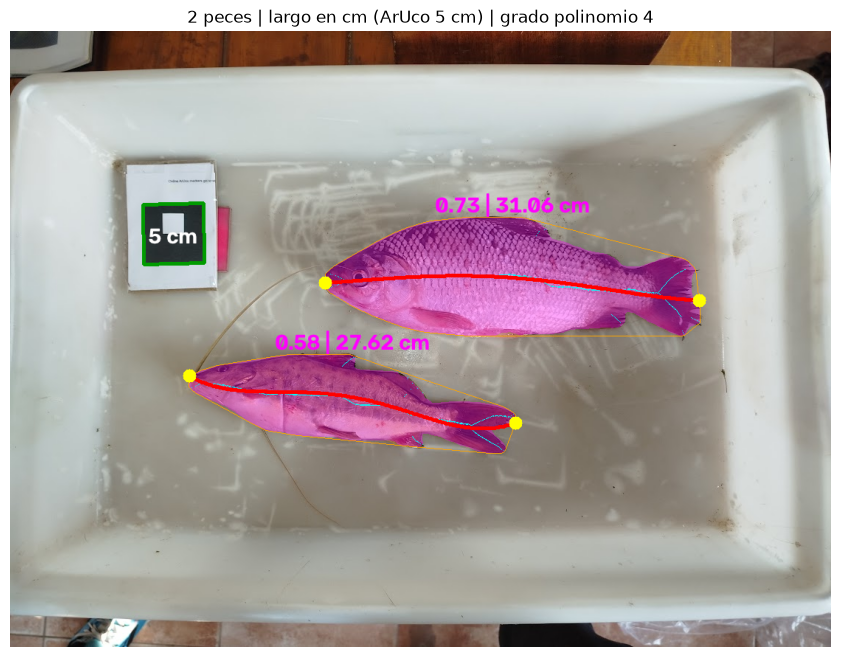

=== example (10).jpg ===
pez 0: largo = 17.93 cm (1882.0 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (10).jpg


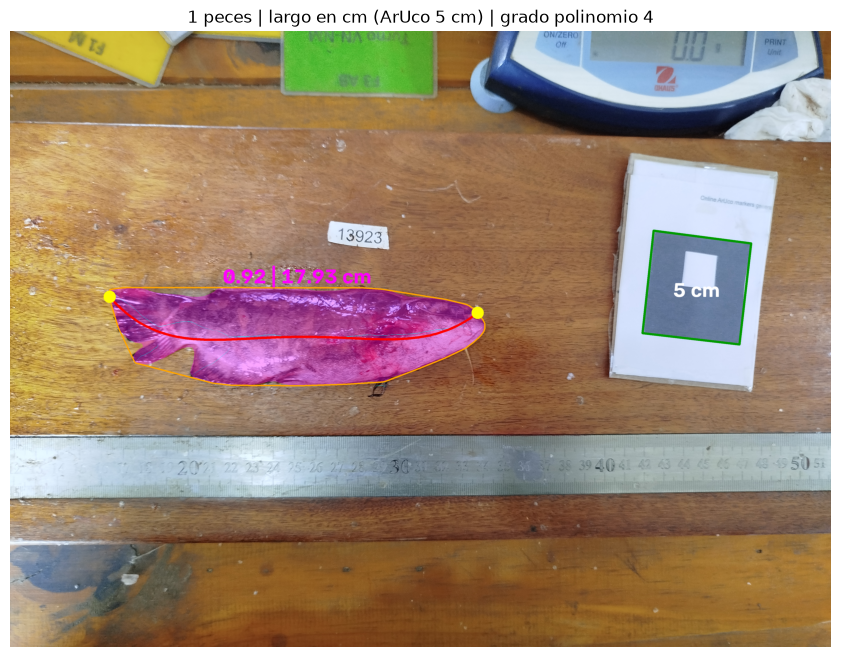

=== example (11).jpg ===
pez 0: largo = 27.05 cm (393.3 px)
pez 1: largo = 19.55 cm (286.1 px)
pez 2: largo = 21.53 cm (321.5 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (11).jpg


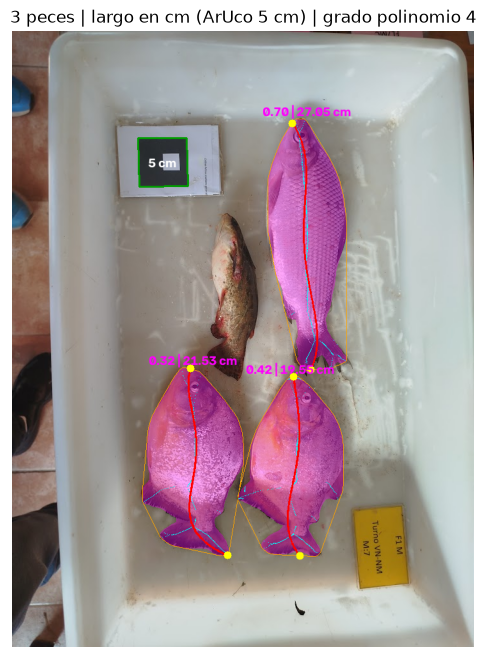

=== example (2).jpg ===
pez 0: largo = 30.62 cm (772.4 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (2).jpg


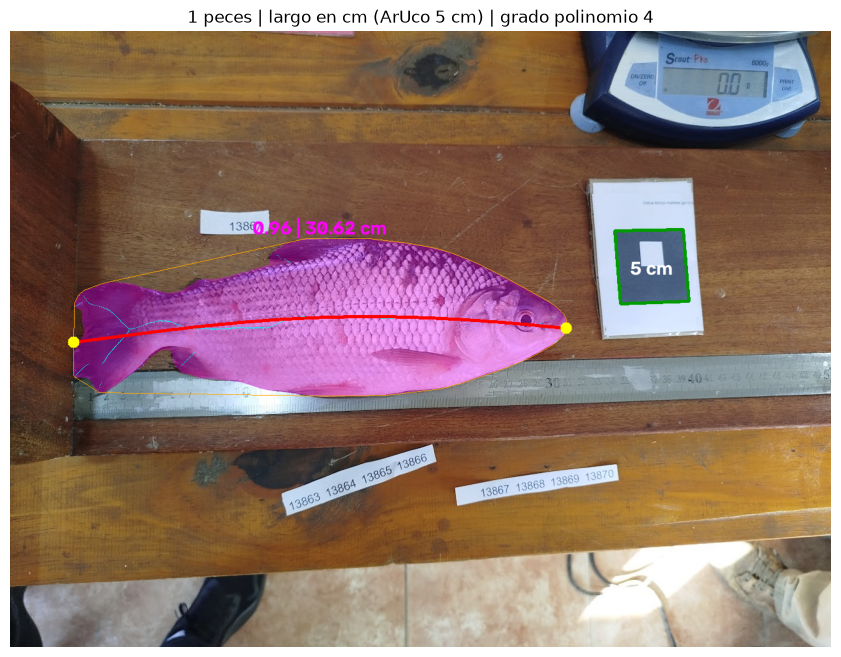

=== example (3).jpg ===
pez 0: largo = 28.45 cm (525.7 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (3).jpg


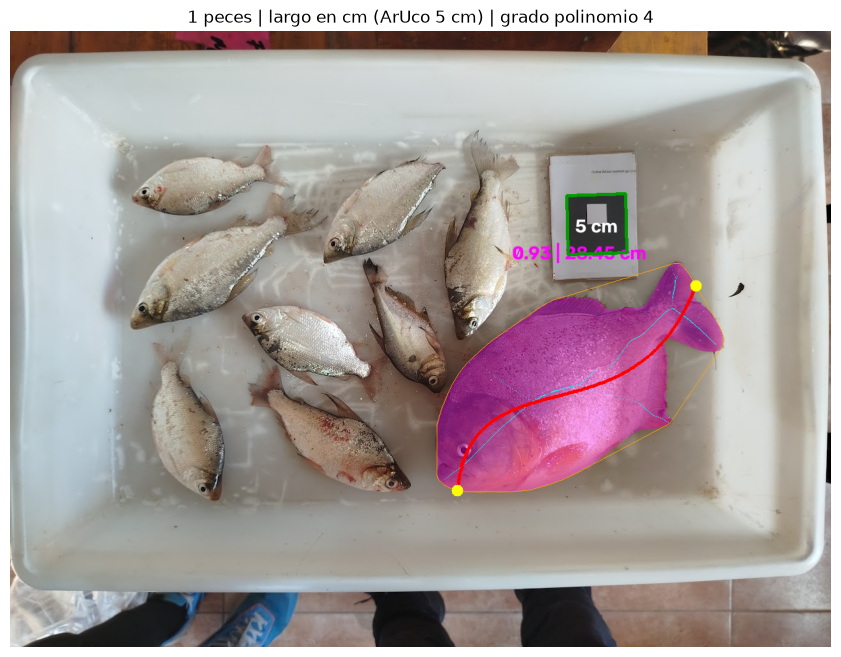

=== example (4).jpg ===
pez 0: largo = 16.94 cm (238.4 px)
pez 1: largo = 17.89 cm (291.9 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (4).jpg


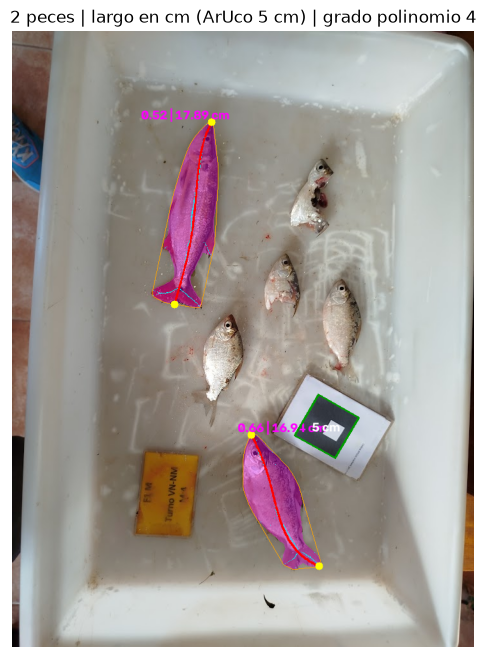

=== example (5).jpg ===
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (5).jpg


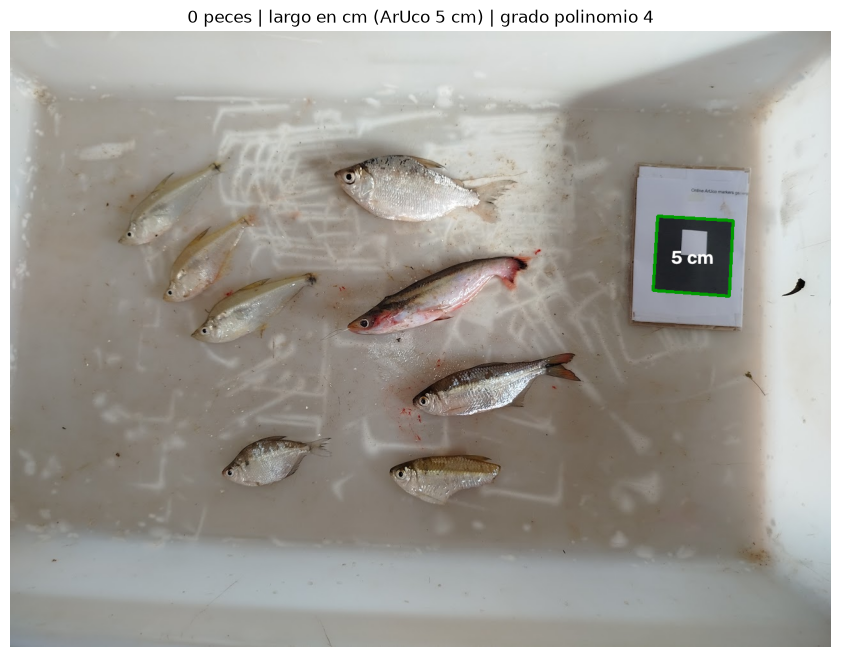

=== example (6).jpg ===
pez 0: largo = 19.52 cm (353.0 px)
pez 1: largo = 18.52 cm (336.4 px)
pez 2: largo = 21.98 cm (408.1 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (6).jpg


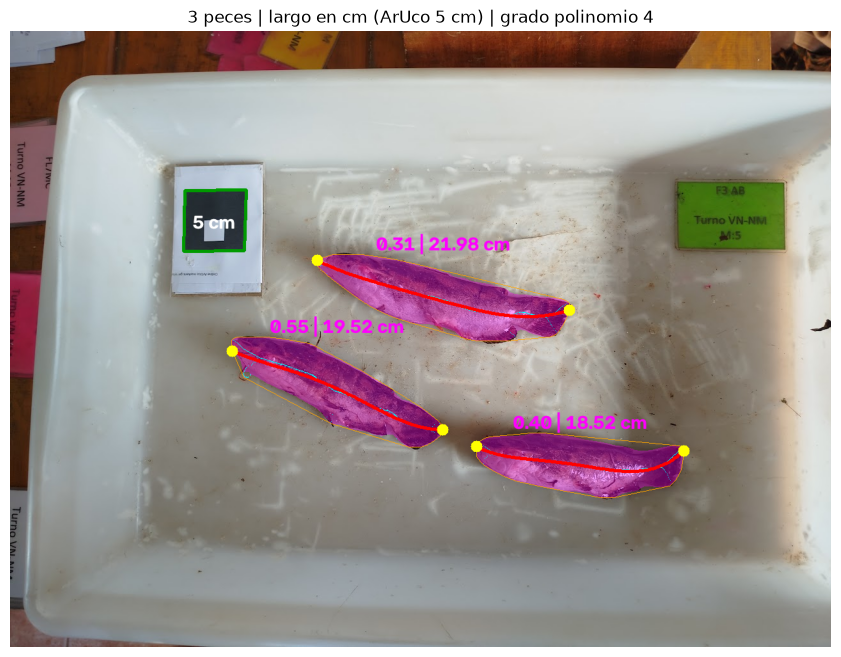

=== example (7).jpg ===
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (7).jpg


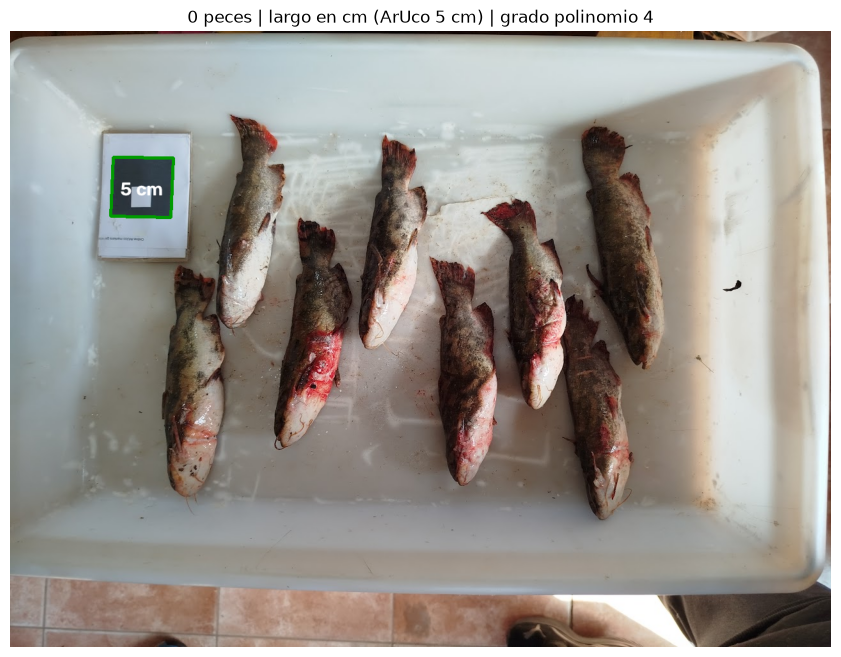

=== example (8).jpg ===
pez 0: largo = 16.57 cm (304.9 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (8).jpg


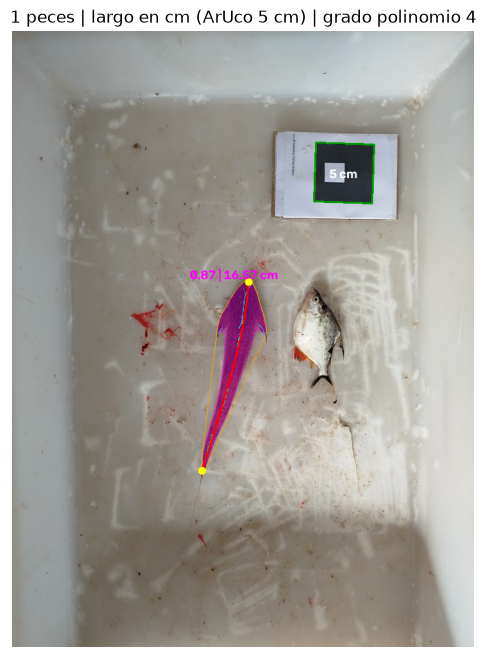

=== example (9).jpg ===
pez 0: largo = 14.89 cm (186.0 px)
pez 1: largo = 22.91 cm (282.6 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/example (9).jpg


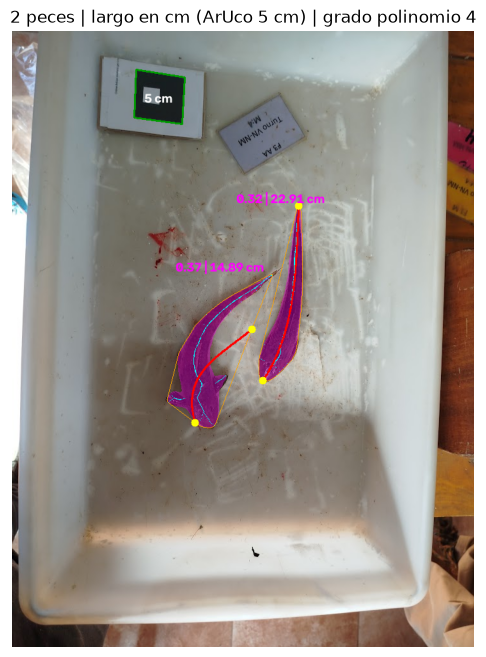

=== mal_angulo.jpg ===
pez 0: largo = 113.58 cm (355.0 px)
lados ArUco (cm): [          5           5           5           5]
Imagen guardada como: examples_processed/mal_angulo.jpg


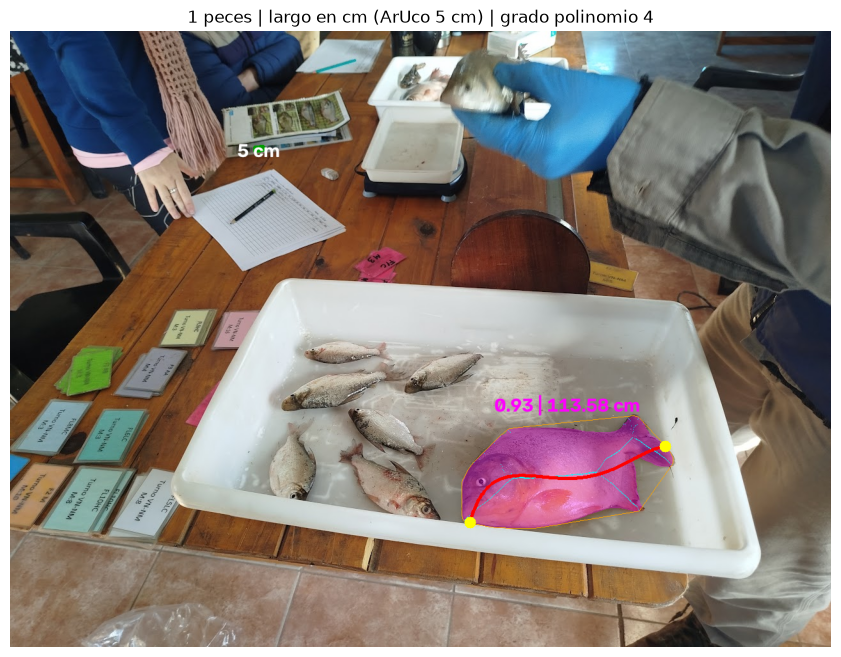

In [3]:
EXAMPLES_DIR = Path("examples")
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for img_path in sorted(p for p in EXAMPLES_DIR.iterdir() if p.suffix.lower() in EXTS):
    print(f"=== {img_path.name} ===")
    try:
        medir_peces(img_path, graficar=True, ruta_salida = f"examples_processed/{img_path.name}")
    except AssertionError as e:      # p. ej. imagen sin ArUco: se salta y sigue con la siguiente
        print(f"  saltada: {e}")
